# NN_L8_ae_pr

**Lecture 8 of Neural Networks and Deep Learning (NN). Precision-recall curves of three fraud detectors on the test part: autoencoder (no labels), PCA reconstruction with 8 components (linear autoencoder, no labels), logistic regression trained with the labels; weighted to the full data.**

Neural Networks and Deep Learning (NN), Lecture 8 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L8/NN_L8_ae_pr/NN_L8_ae_pr.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

PR-AUC (average precision) with sample weights $w_i$ (10 for the sampled legitimate transactions, 1 for frauds).

5785 test transactions in the sample, 75 frauds


PR-AUC of PCA (%) = 7.6   [ae.ap_pca]
PR-AUC of the logistic regression (%) = 80.4   [ae.ap_logit]


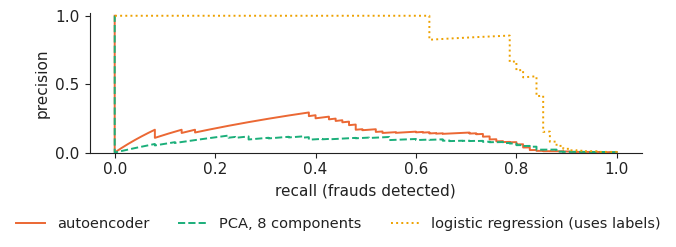

In [3]:
fr = pd.read_csv(REPO + 'lectures/L8/results/' + 'fraud_test_scores.csv')
print(len(fr), 'test transactions in the sample,', int(fr.y.sum()), 'frauds')
from sklearn.metrics import average_precision_score, precision_recall_curve
show('ae.ap_pca', 'PR-AUC of PCA (%)', round(100 * average_precision_score(fr.y, fr.err_pca, sample_weight=fr.weight), 1))
show('ae.ap_logit', 'PR-AUC of the logistic regression (%)', round(100 * average_precision_score(fr.y, fr.p_logit, sample_weight=fr.weight), 1))
fig, ax = plt.subplots(figsize=(6.4, 2.5))
for c, col, ls, lab in [('err_ae', PAL['model'], '-', 'autoencoder'), ('err_pca', PAL['benchmark'], '--', 'PCA, 8 components'),
                        ('p_logit', PAL['alt'], ':', 'logistic regression (uses labels)')]:
    p, r, _ = precision_recall_curve(fr.y, fr[c], sample_weight=fr.weight)
    ax.plot(r, p, ls, color=col, label=lab)
ax.set_xlabel('recall (frauds detected)'); ax.set_ylabel('precision'); ax.set_ylim(0, 1.02)
legend_bottom(fig)
fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('ae_pr.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()